In [1]:
!pip install pandas numpy matplotlib

## Import Python Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
print("Libraries imported successfully")

Libraries imported successfully


## Generate 5000 GPS Records



In [3]:
# Random Seed
np.random.seed(42)

# Total GPS Records
n = 5000

# Generate 1000 Unique Mobile devices
device_ids = np.random.choice(
    [f'DEV_{i:04d}' for i in range(1,1001)],
    size = n)

# Define City area (ludhiana)
center_lat = 30.9010
center_lon = 75.8573

# Generate GPS Location
latitude = np.random.normal(center_lat,0.01,n)
longitude = np.random.normal(center_lon,0.01,n)

# Generate timestamps for 7 days
start_date = pd.Timestamp('2026-11-01')
random_days = np.random.randint(0,7,n)
hours = np.random.randint(0,22,n)
minutes = np.random.randint(0,60,n)

timestamps = (
    start_date
    +pd.to_timedelta(random_days,unit= 'D')
    +pd.to_timedelta(hours,unit = 'h')
    +pd.to_timedelta(minutes, unit = 'm')
)

# Create GPS Dataframe
gps_data = pd.DataFrame({
    'Device_ID' : device_ids,
    'Latitude' : latitude,
    'Longitude' : longitude,
    'timestamp': timestamps
})

print("GPS dataset generated scuucessfully")


GPS dataset generated scuucessfully


## Check Dataset

In [4]:
gps_data.head(5000)

,Device_ID,Latitude,Longitude,timestamp
0,DEV_0103,30.899451,75.852304,2026-11-03 08:08:00
1,DEV_0436,30.908007,75.856688,2026-11-02 11:37:00
2,DEV_0861,30.898216,75.867253,2026-11-06 02:02:00
3,DEV_0271,30.907334,75.851518,2026-11-05 19:53:00
4,DEV_0107,30.885592,75.868433,2026-11-07 16:01:00
...,...,...,...,...
4995,DEV_0290,30.892648,75.840001,2026-11-03 00:07:00
4996,DEV_0295,30.889739,75.859445,2026-11-01 16:27:00
4997,DEV_0451,30.886126,75.852889,2026-11-01 19:17:00
4998,DEV_0904,30.905107,75.842260,2026-11-03 03:12:00


## Verify Dataset

In [5]:
print("Total records:",len(gps_data))
print("Unique Devices:", gps_data['Device_ID'].nunique())
print("Total Columns:",gps_data.shape[1])
print("Missing values:")
print(gps_data.isnull().sum())

Total records: 5000
Unique Devices: 989
Total Columns: 4
Missing values:
Device_ID    0
Latitude     0
Longitude    0
timestamp    0
dtype: int64


## Visualize GPS Locations

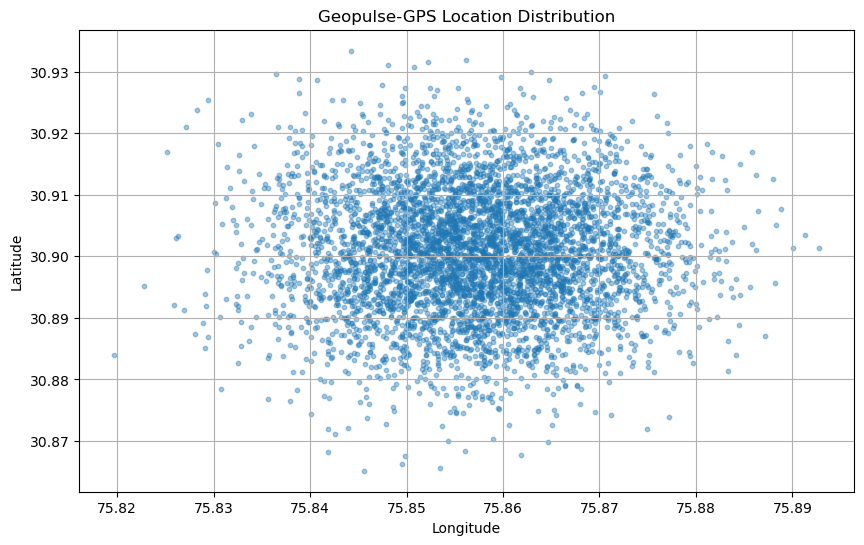

In [6]:
plt.figure(figsize= (10,6))

plt.scatter(
    gps_data['Longitude'],
    gps_data['Latitude'],
    alpha = 0.4,
    s =10)

plt.title("Geopulse-GPS Location Distribution")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid()
plt.show()

## Save CSV File

In [10]:
from pathlib import Path
# Desktop Location 
desktop = Path.home()/"Desktop"

# Create Project Folder
project_folder = desktop/"GeoPulse_Project"

# Create Data Folder
data_folder = project_folder/"data"
data_folder.mkdir(parents = True,
                  exist_ok = True)

print("Project location:",project_folder)
print("Data location:",data_folder)

Project location: C:\Users\hp\Desktop\GeoPulse_Project
Data location: C:\Users\hp\Desktop\GeoPulse_Project\data


In [11]:
gps_data.to_csv(
    data_folder/"raw_gps_data.csv",
    index = False)
print("GPS data saved successfuly")

GPS data saved successfuly
